#Premiers pas avec les images

Ce notebook vous aidera à faire vos premiers pas dans l'apprentissage du traitement d'images et de la vision par ordinateur avec OpenCV. Vous apprendrez quelques notions importantes à travers des exemples simples. Dans ce notebook, vous apprendrez les points suivants :

* Lire une image
* Vérifier les attributs d'une image comme le type de données et la forme
* Représentation matricielle d'une image en Numpy
* Images en couleur et séparation/fusion des canaux d'image
* Afficher des images avec matplotlib
* Enregistrer des images

## Import des librairies

In [1]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt

from zipfile import ZipFile
from urllib.request import urlretrieve

from IPython.display import Image

%matplotlib inline

##  Téléchargement des assets

La fonction *download_and_unzip(...)* est utilisée pour télécharger et extraire les ressources du notebook.

In [2]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [3]:
URL = r"https://www.dropbox.com/s/qhhlqcica1nvtaw/opencv_bootcamp_assets_NB1.zip?dl=1"

asset_zip_path = os.path.join(os.getcwd(), "opencv_bootcamp_assets_NB1.zip")

# Download if assest ZIP does not exists.
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path)

##  Affichage direct de l'image
Nous utiliserons les éléments suivants comme nos images d’exemple. Nous utiliserons la fonction image d’ipython pour charger et afficher l’image.

In [ ]:
# Display 18x18 pixel image.
Image(filename="checkerboard_18x18.png")

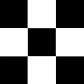

In [ ]:
# Display 84x84 pixel image.
Image(filename="checkerboard_84x84.jpg")

# Lire des images avec OpenCV

OpenCV permet de lire différents types d’images (JPG, PNG, etc.). Vous pouvez charger des images en niveaux de gris, des images en couleur ou encore des images avec canal Alpha. Il utilise la fonction **`cv2.imread()`** qui a la syntaxe suivante :

### Syntaxe

``` python
retval = cv2.imread( filename[, flags] )
```

`retval`: : Est l’image si elle est chargée avec succès. Sinon, c’est None. Cela peut se produire si le nom de fichier est incorrect ou si le fichier est corrompu.

La fonction a **1 argument d’entrée requis** et un indicateur optionnel :

1. `filename` : Il peut s’agir d’un chemin absolu ou relatif. Il s’agit d’un argument obligatoire.

2. `Flags` : Ces indicateurs sont utilisés pour lire une image dans un format particulier (par exemple, niveaux de gris / couleur / avec canal alpha). Il s’agit d’un argument optionnel avec une valeur par défaut de cv2.IMREAD_COLOR ou 1, qui charge l’image en couleur.

Avant de passer à quelques exemples, examinons également certains des flags disponibles.

**Flags**
1. **`cv2.IMREAD_GRAYSCALE`** or **`0`**: Charge l'image en mode niveaux de gris

2. **`cv2.IMREAD_COLOR`** or **`1`**: Charge une image en couleur. Toute transparence de l'image sera ignorée. C'est le drapeau par défaut.
3. **`cv2.IMREAD_UNCHANGED`** or **`-1`**: Charge l’image telle quelle, y compris le canal alpha.


### <font color="green">OpenCV Documentation</font>

1. **`Imread`**:  <a href="https://docs.opencv.org/4.5.1/d4/da8/group__imgcodecs.html#ga288b8b3da0892bd651fce07b3bbd3a56" target="_blank">Documentation link</a>

2. **`ImreadModes`**: <a href="https://docs.opencv.org/4.5.1/d8/d6a/group__imgcodecs__flags.html#ga61d9b0126a3e57d9277ac48327799c80" target="_blank">Documentation link</a>


In [ ]:
# Read image as gray scale.
cb_img = cv2.imread("checkerboard_18x18.png", 0)

# Print the image data (pixel values), element of a 2D numpy array.
# Each pixel value is 8-bits [0,255]
print(cb_img)
print(type(cb_img))

[[  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [255 255 255 255 255 255   0   0   0   0   0   0 255 255 255 255 255 255]
 [  0   0   0   0   0   0 255 255 255 255 255 255   0   0   0   0   0   0]
 [  0   0   0   0   0   0

In [ ]:
type(cb_img)

numpy.ndarray

## Afficher les attributs d'une image

In [ ]:
# print the size  of image
print("Image size (H, W) is:", cb_img.shape)

# print data-type of image
print("Data type of image is:", cb_img.dtype)

Image size (H, W) is: (18, 18)
Data type of image is: uint8


## Afficher des images avec Matplotlib

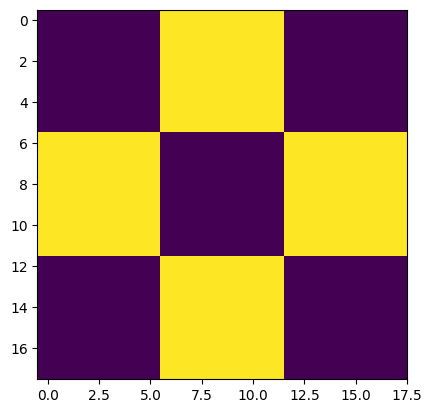

In [ ]:
# Display image.
plt.imshow(cb_img)

### Quel est le problème ?

Même si l'image a été lue comme une image en niveaux de gris, elle ne s'affichera pas nécessairement en niveaux de gris lors de l'utilisation de imshow(). matplotlib utilise différentes cartes de couleurs et il est possible que la carte de couleurs en niveaux de gris ne soit pas définie.

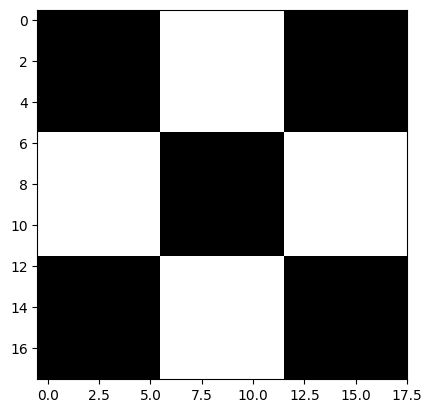

In [ ]:
# Set color map to gray scale for proper rendering.
plt.imshow(cb_img, cmap="gray")

## 2ème exemple

[[  0   0  15  20   1 134 233 253 253 253 255 229 130   1  29   2   0   0]
 [  0   1   5  18   0 137 232 255 254 247 255 228 129   0  24   2   0   0]
 [  7   5   2  28   2 139 230 254 255 249 255 226 128   0  27   3   2   2]
 [ 25  27  28  38   0 129 236 255 253 249 251 227 129   0  36  27  27  27]
 [  2   0   0   4   2 130 239 254 254 254 255 230 126   0   4   2   0   0]
 [132 129 131 124 121 163 211 226 227 225 226 203 164 125 125 129 131 131]
 [234 227 230 229 232 205 151 115 125 124 117 156 205 232 229 225 228 228]
 [254 255 255 251 255 222 102   1   0   0   0 120 225 255 254 255 255 255]
 [254 255 254 255 253 225 104   0  50  46   0 120 233 254 247 253 251 253]
 [252 250 250 253 254 223 105   2  45  50   0 127 223 255 251 255 251 253]
 [254 255 255 252 255 226 104   0   1   1   0 120 229 255 255 254 255 255]
 [233 235 231 233 234 207 142 106 108 102 108 146 207 235 237 232 231 231]
 [132 132 131 132 130 175 207 223 224 224 224 210 165 134 130 136 134 134]
 [  1   1   3   0   0 129

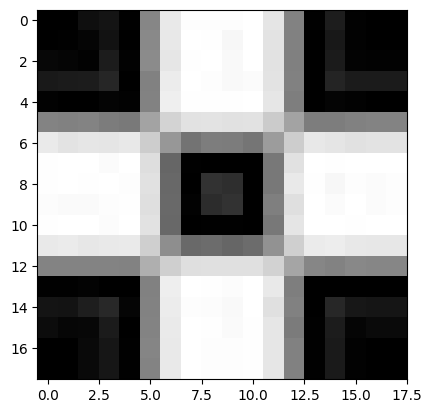

In [ ]:
# Read image as gray scale.
cb_img_fuzzy = cv2.imread("checkerboard_fuzzy_18x18.jpg", 0)

# print image
print(cb_img_fuzzy)

# Display image.
plt.imshow(cb_img_fuzzy, cmap="gray")

## Images de couleurs
Jusqu’à présent, nous avons utilisé des images en niveaux de gris. Discutons maintenant des images en couleur.


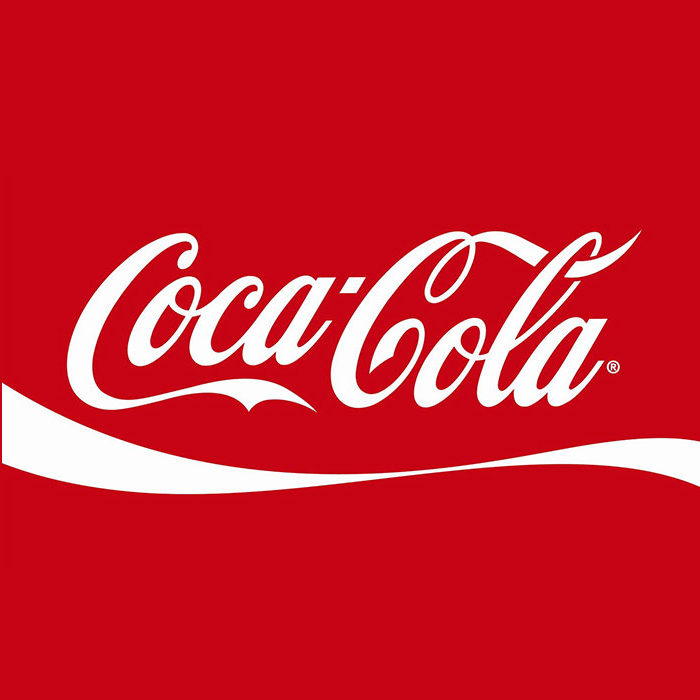

In [ ]:
# Read and display Coca-Cola logo.
Image("coca-cola-logo.png")

## Lire et afficher des images en couleur
Lisons une image en couleur et vérifions les paramètres. Remarquez la dimension de l’image.

In [ ]:
# Read in image
coke_img = cv2.imread("coca-cola-logo.png", 1)

# print the size  of image
print("Image size (H, W, C) is:", coke_img.shape)

# print data-type of image
print("Data type of image is:", coke_img.dtype)

Image size (H, W, C) is: (700, 700, 3)
Data type of image is: uint8


## Affichage de l'image

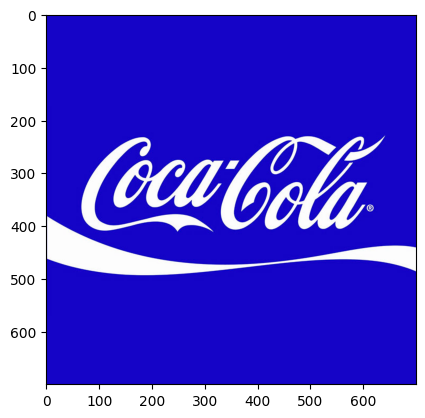

In [ ]:
plt.imshow(coke_img)
#  What happened?

La couleur affichée ci-dessus est différente de l'image réelle. Cela est dû au fait que matplotlib attend l'image au format RGB tandis qu'OpenCV stocke les images au format BGR. Ainsi, pour un affichage correct, nous devons inverser les canaux de l'image. Nous parlerons des canaux dans les sections ci-dessous.

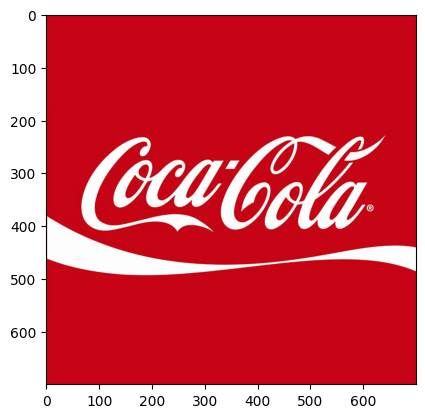

In [ ]:
coke_img_channels_reversed = coke_img[:, :, ::-1]
plt.imshow(coke_img_channels_reversed)

## Séparer et merger les canaux de couleurs


* **`cv2.split()`** Divise un tableau multicanal en plusieurs tableaux à canal unique.

* **`cv2.merge()`** Fusionne plusieurs tableaux pour créer un seul tableau multicanal. Toutes les matrices d'entrée doivent avoir la même taille.

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

<a href="https://docs.opencv.org/4.5.1/d2/de8/group__core__array.html#ga0547c7fed86152d7e9d0096029c8518a" target="_blank">Documentation link</a>

Text(0.5, 1.0, 'Merged Output')

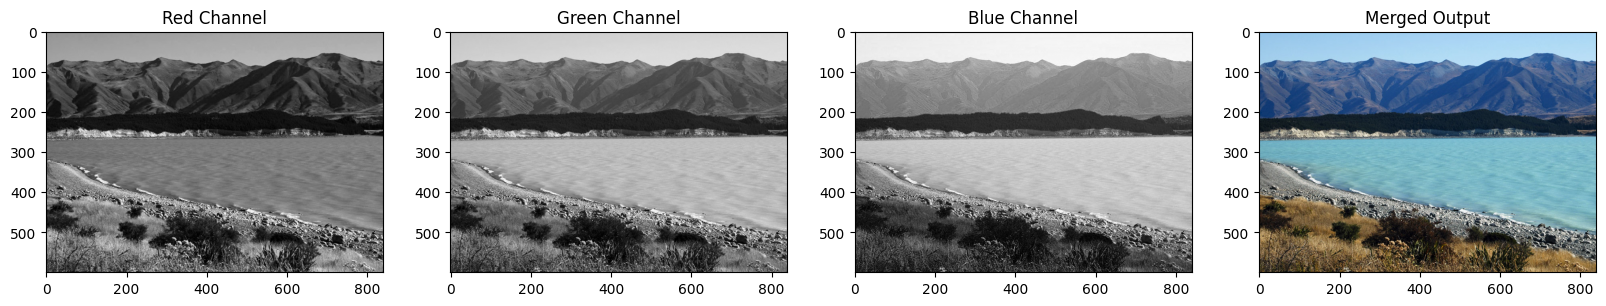

In [ ]:
# Split the image into the B,G,R components
img_NZ_bgr = cv2.imread("New_Zealand_Lake.jpg", cv2.IMREAD_COLOR)
b, g, r = cv2.split(img_NZ_bgr)

# Show the channels
plt.figure(figsize=[20, 5])

plt.subplot(141);plt.imshow(r, cmap="gray");plt.title("Red Channel")
plt.subplot(142);plt.imshow(g, cmap="gray");plt.title("Green Channel")
plt.subplot(143);plt.imshow(b, cmap="gray");plt.title("Blue Channel")

# Merge the individual channels into a BGR image
imgMerged = cv2.merge((b, g, r))

# Show the merged output
plt.subplot(144)
plt.imshow(imgMerged[:, :, ::-1])
plt.title("Merged Output")

In [ ]:
print(b.shape)

#plt.imshow(b)

(600, 840)


## Converting to different Color Spaces


**`cv2.cvtColor()`** Convertit une image d’un espace colorimétrique à un autre. La fonction convertit une image d’entrée d’un espace colorimétrique à un autre. En cas de transformation vers ou depuis l’espace colorimétrique RGB, l’ordre des canaux doit être spécifié explicitement (RGB ou BGR). Notez que le format de couleur par défaut dans OpenCV est souvent appelé RGB mais il est en réalité BGR (les octets sont inversés). Ainsi, le premier octet d’une image couleur standard (24 bits) sera un composant Bleu de 8 bits, le deuxième octet sera Vert, et le troisième sera Rouge. Les quatrième, cinquième et sixième octets correspondraient alors au deuxième pixel (Bleu, puis Vert, puis Rouge), et ainsi de suite.

### <font style="color:rgb(8,133,37)">Syntaxe </font>
``` python
dst = cv2.cvtColor( src, code )
```

`dst`: Output de l'image, elle a la même taille que `src`.

La fonction a **2 arguments requis**:

1. `src` image d'entrée : non signé 8 bits, non signé 16 bits ( CV_16UC... ), ou virgule flottante en simple précision.

2. `code` code de conversion d’espace colorimétrique (voir ColorConversionCodes).

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

1. **`cv2.cvtColor`**: <a href="https://docs.opencv.org/3.4/d8/d01/group__imgproc__color__conversions.html#ga397ae87e1288a81d2363b61574eb8cab" target="_blank">Documentation link</a>  

2. **`ColorConversionCodes`**: <a href="https://docs.opencv.org/4.5.1/d8/d01/group__imgproc__color__conversions.html#ga4e0972be5de079fed4e3a10e24ef5ef0" target="_blank">Documentation link</a>


### Convertir du BGR en RGB

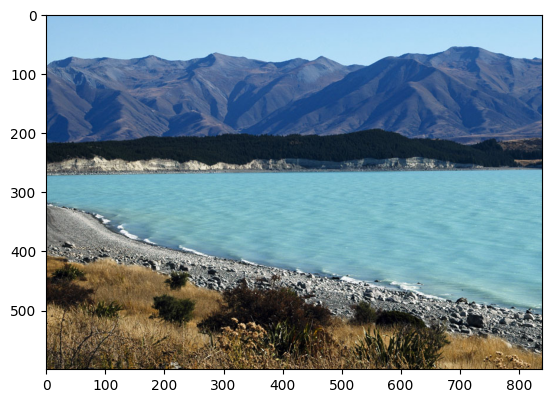

In [ ]:
# OpenCV stores color channels in a differnet order than most other applications (BGR vs RGB).
img_NZ_rgb = cv2.cvtColor(img_NZ_bgr, cv2.COLOR_BGR2RGB)
plt.imshow(img_NZ_rgb)
#plt.imshow(img_NZ_bgr)

### Convertir vers le format HSV

Contrairement à l’espace RGB, l’espace HSV vous permet d’isoler le vert par exemple, peu importe son intensité sa luminosité.

* Teinte: mesure la tonalité d’une couleur dans le spectre lumineux.
* Saturation: mesure l’intensité de la couleur du pixel.
* Value: Measures the brightness of the pixel.

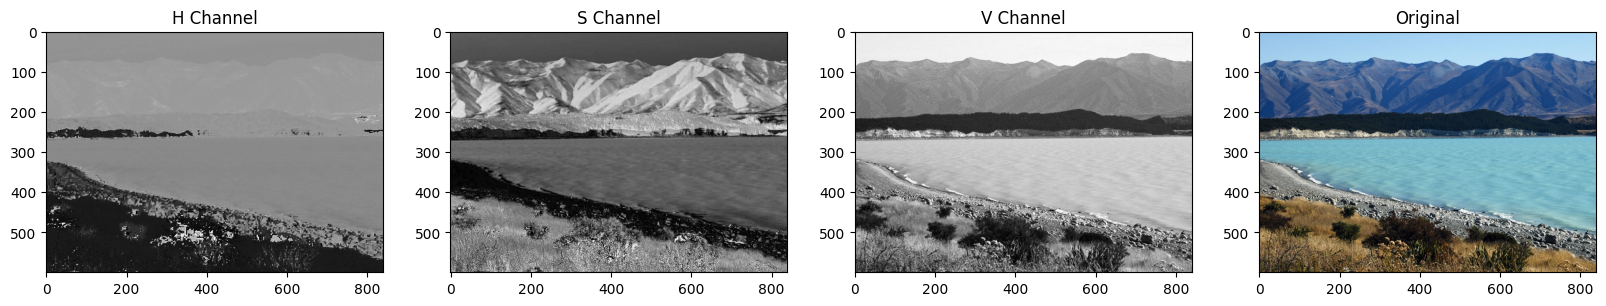

In [ ]:
img_hsv = cv2.cvtColor(img_NZ_bgr, cv2.COLOR_BGR2HSV)

# Split the image into the B,G,R components
h,s,v = cv2.split(img_hsv)

# Show the channels
plt.figure(figsize=[20,5])
plt.subplot(141);plt.imshow(h, cmap="gray");plt.title("H Channel");
plt.subplot(142);plt.imshow(s, cmap="gray");plt.title("S Channel");
plt.subplot(143);plt.imshow(v, cmap="gray");plt.title("V Channel");
plt.subplot(144);plt.imshow(img_NZ_rgb);   plt.title("Original");

## Sauvegarder une image

Enregistrer l’image est aussi simple que de lire une image dans OpenCV. Nous utilisons la fonction cv2.imwrite() avec deux arguments. Le premier est le nom du fichier, le second argument est l’objet image.

La fonction imwrite enregistre l’image dans le fichier spécifié. Le format de l’image est choisi en fonction de l’extension du nom de fichier (voir cv::imread pour la liste des extensions). En général, seules les images à canal unique 8 bits ou à trois canaux (avec l’ordre de canaux 'BGR') peuvent être enregistrées à l’aide de cette fonction (voir la documentation OpenCV pour plus de détails).


### <font style="color:rgb(8,133,37)">Function Syntax </font>
``` python
cv2.imwrite( filename, img[, params] )
```

### <font style="color:rgb(8,133,37)">OpenCV Documentation</font>

1. **`Imwrite`**: <a href="https://docs.opencv.org/4.5.1/d4/da8/group__imgcodecs.html#gabbc7ef1aa2edfaa87772f1202d67e0ce" target="_blank">Documentation link</a>

2. **`ImwriteFlags`**: <a href="https://docs.opencv.org/4.5.1/d8/d6a/group__imgcodecs__flags.html#ga292d81be8d76901bff7988d18d2b42ac" target="_blank">Documentation link</a>

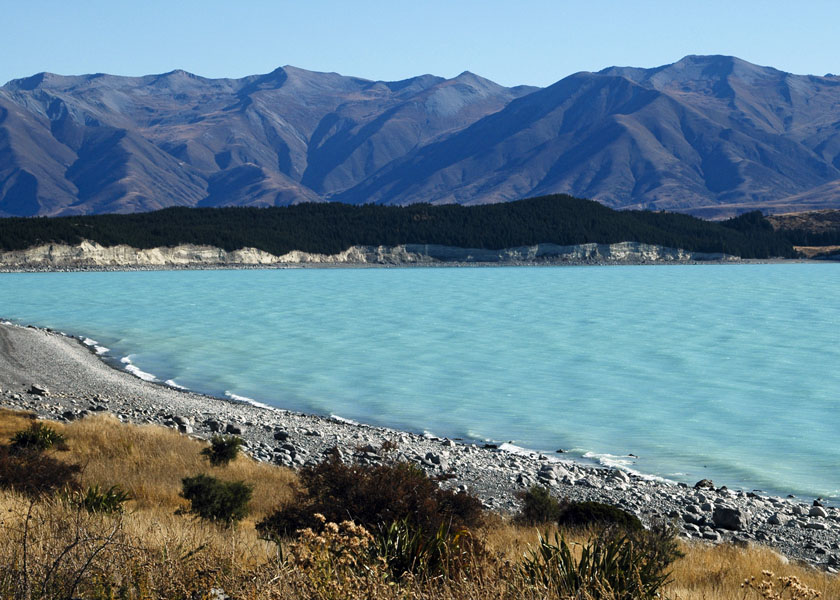

In [ ]:
# save the image
cv2.imwrite("New_Zealand_Lake_SAVED.png", img_NZ_bgr)

Image(filename='New_Zealand_Lake_SAVED.png')

In [ ]:
# read the image as Color
img_NZ_bgr = cv2.imread("New_Zealand_Lake_SAVED.png", cv2.IMREAD_COLOR)
print("img_NZ_bgr shape (H, W, C) is:", img_NZ_bgr.shape)

# read the image as Grayscaled
img_NZ_gry = cv2.imread("New_Zealand_Lake_SAVED.png", cv2.IMREAD_GRAYSCALE)
print("img_NZ_gry shape (H, W) is:", img_NZ_gry.shape)

img_NZ_bgr shape (H, W, C) is: (600, 840, 3)
img_NZ_gry shape (H, W) is: (600, 840)


## Exercice :

- numpy + cv2.imwrite

Créer une image dans laquelle la partie en haut à gauche est noire et la partie en bas à droite est en blanc, la diagonale sépare les 2 couleurs. image de taille 200/200